In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv(
    "../data/cleaned/fraud_features.csv"
)

In [3]:
df.head()

,Transaction_Amount,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Transaction_Hour,Transaction_Month,Amount_vs_Average,Merchant_Category_Entertainment,Merchant_Category_Fashion,...,Device_Type_Mobile,Device_Type_POS,Location_Chennai,Location_Delhi,Location_Hyderabad,Location_Kolkata,Location_Mumbai,Location_Pune,Suspicious_Keyword_Yes,Fraudulent
0,37.54,0,94,417.40,1492,7,10,0.089938,0,0,...,0,1,0,0,0,0,0,0,0,0
1,240.81,0,76,335.47,66,8,9,0.717829,0,0,...,1,0,0,0,0,0,0,0,0,0
2,105.34,0,60,432.03,216,15,7,0.243826,1,0,...,1,0,0,0,0,0,0,0,0,0
3,73.04,0,68,488.30,449,17,10,0.149580,0,0,...,0,0,0,0,0,1,0,0,0,0
4,13.57,0,57,437.03,754,0,9,0.031050,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
df.shape

(5000, 29)

In [5]:
target = "Fraudulent"

X = df.drop(columns=[target])
y = df[target]

In [6]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5000, 28)
Target shape: (5000,)


In [13]:
y.value_counts()

Fraudulent
0    4518
1     482
Name: count, dtype: int64

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (4000, 28)
Testing features: (1000, 28)
Training target: (4000,)
Testing target: (1000,)


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

In [19]:
## Logistic Regression and Scaler
## Logistic Regression is sensitive to feature scale, 
## this is where we should apply scaling inside the model workflow

In [20]:
## Scale the Training and Testing Data

In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
scaler.fit_transform(X_train)

array([[-0.10114996, -0.30820516, -1.03819015, ..., -0.41388776,
         2.416114  , -0.23420572],
       [-0.92097962, -0.30820516,  0.59158731, ..., -0.41388776,
        -0.41388776, -0.23420572],
       [-0.7111672 , -0.30820516, -1.42372891, ..., -0.41388776,
         2.416114  , -0.23420572],
       ...,
       [-0.94788841, -0.30820516, -0.51245548, ..., -0.41388776,
        -0.41388776, -0.23420572],
       [-0.53664083,  3.24459204,  0.41634243, ..., -0.41388776,
        -0.41388776, -0.23420572],
       [-0.18708039, -0.30820516,  1.11732198, ...,  2.416114  ,
        -0.41388776, -0.23420572]], shape=(4000, 28))

In [23]:
scaler.transform(X_test)

array([[ 1.54371341, -0.30820516, -1.66907175, ..., -0.41388776,
        -0.41388776,  4.26975049],
       [-0.79938234, -0.30820516,  0.50396487, ..., -0.41388776,
        -0.41388776, -0.23420572],
       [-0.49234287, -0.30820516, -0.91551873, ...,  2.416114  ,
        -0.41388776,  4.26975049],
       ...,
       [-0.25904872,  3.24459204,  0.7668322 , ..., -0.41388776,
        -0.41388776, -0.23420572],
       [-0.30360054, -0.30820516, -0.63512691, ..., -0.41388776,
        -0.41388776, -0.23420572],
       [-0.71230955, -0.30820516,  1.5554342 , ..., -0.41388776,
        -0.41388776, -0.23420572]], shape=(1000, 28))

In [24]:
## Logistic Regression Model

In [25]:
logistic_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

In [26]:
logistic_model.fit(
    X_train_scaled,
    y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [27]:
y_pred_logistic = logistic_model.predict(
    X_test_scaled
)

In [28]:
print(y_pred_logistic[:20])

[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [29]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_logistic
})

comparison.head(20)

,Actual,Predicted
0,0,1
1,0,0
2,1,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,0
8,0,0
9,0,0


In [30]:
## Evaluation Metric

In [31]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

In [33]:
## Confusion Matrix

In [34]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic
)

cm_logistic

array([[884,  20],
       [ 77,  19]])

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

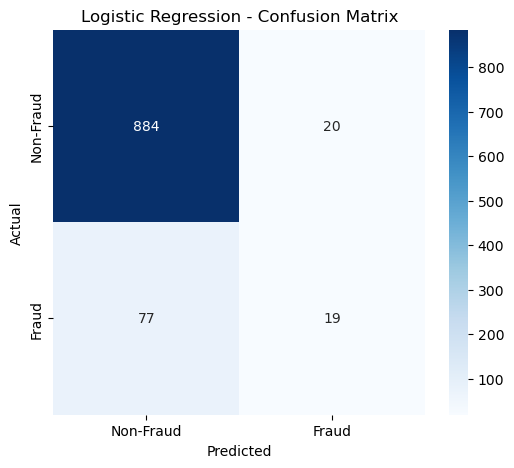

In [36]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [37]:
accuracy_logistic = accuracy_score(
    y_test,
    y_pred_logistic
)

print("Logistic Regression Accuracy:", accuracy_logistic)

Logistic Regression Accuracy: 0.903


In [40]:
print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

              precision    recall  f1-score   support

           0       0.92      0.98      0.95       904
           1       0.49      0.20      0.28        96

    accuracy                           0.90      1000
   macro avg       0.70      0.59      0.61      1000
weighted avg       0.88      0.90      0.88      1000



In [41]:
##  Decision Tree 

In [42]:
from sklearn.tree import DecisionTreeClassifier

In [43]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

In [44]:
decision_tree_model.fit(
    X_train,
    y_train
)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [45]:
y_pred_tree = decision_tree_model.predict(
    X_test
)

In [46]:
print(y_pred_tree[:20])

[1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0]


In [47]:
comparison_tree = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_tree
})

comparison_tree.head(20)

,Actual,Predicted
0,0,1
1,0,0
2,1,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,0
8,0,0
9,0,0


In [48]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree
)

cm_tree

array([[823,  81],
       [ 63,  33]])

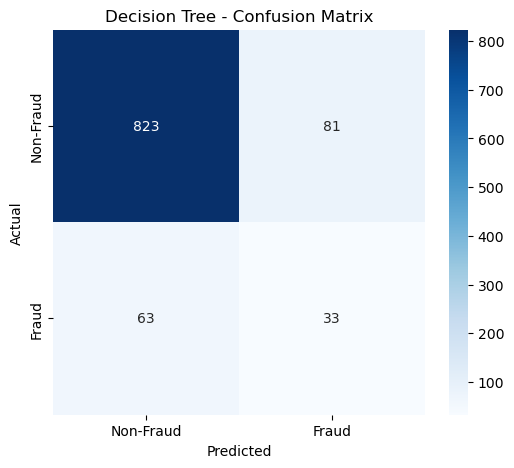

In [49]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [50]:
accuracy_tree = accuracy_score(
    y_test,
    y_pred_tree
)

print("Decision Tree Accuracy:", accuracy_tree)

Decision Tree Accuracy: 0.856


In [51]:
print(
    classification_report(
        y_test,
        y_pred_tree
    )
)

              precision    recall  f1-score   support

           0       0.93      0.91      0.92       904
           1       0.29      0.34      0.31        96

    accuracy                           0.86      1000
   macro avg       0.61      0.63      0.62      1000
weighted avg       0.87      0.86      0.86      1000



In [53]:
## Random Forest

In [54]:
from sklearn.ensemble import RandomForestClassifier

In [55]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [56]:
random_forest_model.fit(
    X_train,
    y_train
)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [57]:
y_pred_rf = random_forest_model.predict(
    X_test
)

In [58]:
print(y_pred_rf[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [59]:
comparison_rf = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_rf
})

comparison_rf.head(20)

,Actual,Predicted
0,0,0
1,0,0
2,1,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,0
8,0,0
9,0,0


In [60]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

cm_rf

array([[895,   9],
       [ 86,  10]])

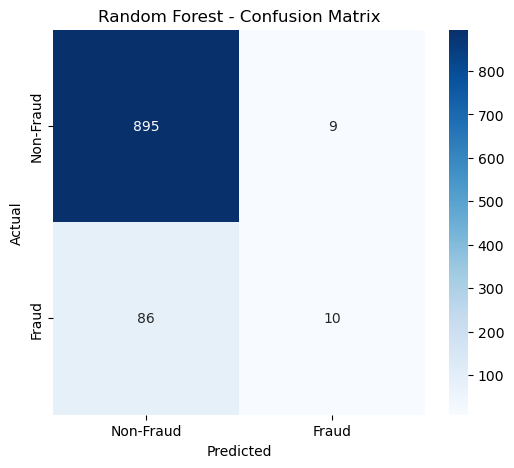

In [61]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [62]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.905


In [63]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.91      0.99      0.95       904
           1       0.53      0.10      0.17        96

    accuracy                           0.91      1000
   macro avg       0.72      0.55      0.56      1000
weighted avg       0.88      0.91      0.88      1000



In [64]:
## Compare Model Accuracy

In [65]:
model_accuracy = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_rf
    ]
})

model_accuracy

,Model,Accuracy
0,Logistic Regression,0.903
1,Decision Tree,0.856
2,Random Forest,0.905


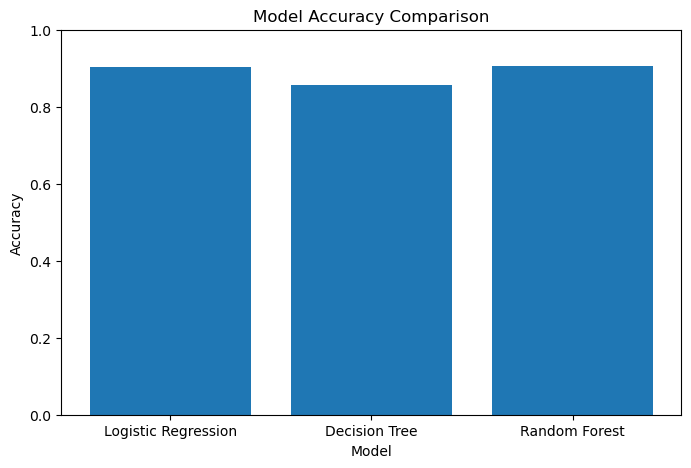

In [70]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_accuracy["Model"],
    model_accuracy["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

In [75]:
## Compare Fraud Class Performance
## we compare Precision, Recall, and F1-score specifically for Fraud - 1
## here we dont use pos_label=1, pos_label=0 by default it 1

In [73]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [76]:
fraud_metrics = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf)
    ]
})

fraud_metrics

,Model,Precision,Recall,F1-Score
0,Logistic Regression,0.487179,0.197917,0.281481
1,Decision Tree,0.289474,0.343750,0.314286
2,Random Forest,0.526316,0.104167,0.173913


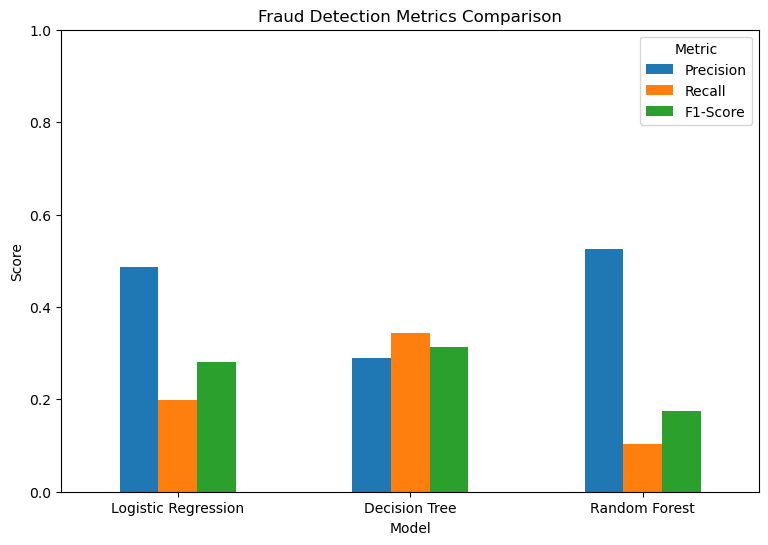

In [81]:
fraud_metrics.set_index("Model").plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Fraud Detection Metrics Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.show()

In [82]:
## Gradient Boosting

In [83]:
from sklearn.ensemble import GradientBoostingClassifier

In [84]:
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

In [85]:
gradient_boosting_model.fit(
    X_train,
    y_train
)

,loss,'log_loss'
,learning_rate,0.05
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [86]:
y_pred_gb = gradient_boosting_model.predict(
    X_test
)

In [87]:
print(y_pred_gb[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [88]:
comparison_gb = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_gb
})

comparison_gb.head(20)

,Actual,Predicted
0,0,0
1,0,0
2,1,0
3,0,0
4,0,0
5,0,0
6,0,0
7,1,0
8,0,0
9,0,0


In [89]:
cm_gb = confusion_matrix(
    y_test,
    y_pred_gb
)

cm_gb

array([[888,  16],
       [ 81,  15]])

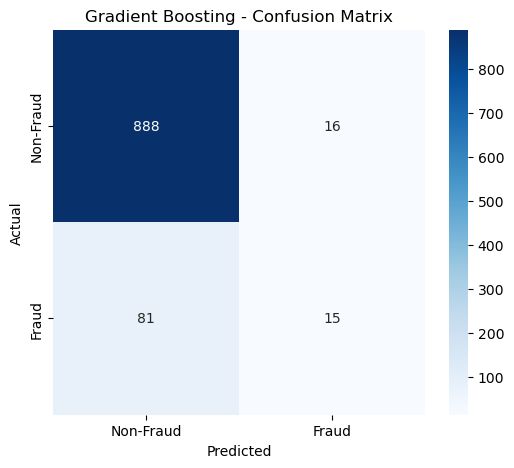

In [90]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Fraud", "Fraud"],
    yticklabels=["Non-Fraud", "Fraud"]
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [91]:
accuracy_gb = accuracy_score(
    y_test,
    y_pred_gb
)

print("Gradient Boosting Accuracy:", accuracy_gb)

Gradient Boosting Accuracy: 0.903


In [92]:
print(
    classification_report(
        y_test,
        y_pred_gb
    )
)

              precision    recall  f1-score   support

           0       0.92      0.98      0.95       904
           1       0.48      0.16      0.24        96

    accuracy                           0.90      1000
   macro avg       0.70      0.57      0.59      1000
weighted avg       0.87      0.90      0.88      1000



In [93]:
model_accuracy = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_rf,
        accuracy_gb
    ]
})

model_accuracy

,Model,Accuracy
0,Logistic Regression,0.903
1,Decision Tree,0.856
2,Random Forest,0.905
3,Gradient Boosting,0.903


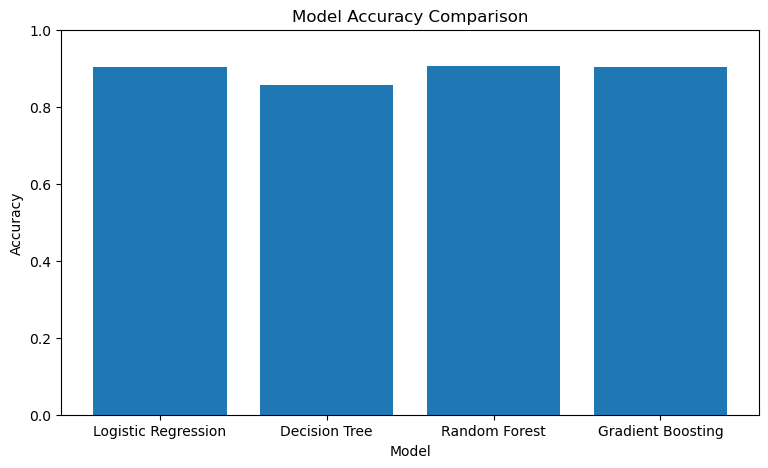

In [94]:
plt.figure(figsize=(9, 5))

plt.bar(
    model_accuracy["Model"],
    model_accuracy["Accuracy"]
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.show()

In [95]:
## Final Fraud Metrics Comparison

In [96]:
fraud_metrics = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ]
})

fraud_metrics

,Model,Precision,Recall,F1-Score
0,Logistic Regression,0.487179,0.197917,0.281481
1,Decision Tree,0.289474,0.343750,0.314286
2,Random Forest,0.526316,0.104167,0.173913
3,Gradient Boosting,0.483871,0.156250,0.236220


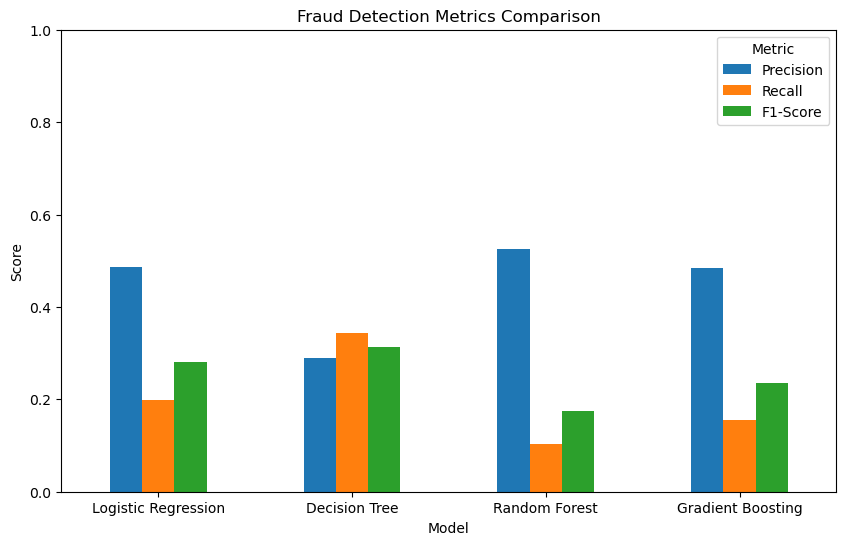

In [97]:
fraud_metrics.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Fraud Detection Metrics Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metric")

plt.show()

In [120]:
## ROC-AUC Metric
##ROC-AUC evaluates how well the model separates 
##Fraud (1) from Non-Fraud (0) across different classification thresholds.
## ROC-AUC uses these probability/score values to see how well the model separates Fraud (1) from Non-Fraud (0).

In [101]:
from sklearn.metrics import roc_auc_score

In [104]:
## probability of class 1 using [:,1]

In [115]:
## Logistic Regression Probability Scores using predict_proba

In [105]:
y_prob_logistic = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

In [116]:
## Decision Tree Probability Scores using predict_proba

In [108]:
y_prob_tree = decision_tree_model.predict_proba(
    X_test
)[:, 1]

In [117]:
##Random Forest Probability Scores using predict_proba

In [111]:
y_prob_rf = random_forest_model.predict_proba(
    X_test
)[:, 1]

In [118]:
### Gradient Boosting Probability Scores using predict_proba

In [113]:
y_prob_gb = gradient_boosting_model.predict_proba(
    X_test
)[:, 1]

In [121]:
## Calculate ROC-AUC for All Models

In [122]:
roc_auc_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_logistic),
        roc_auc_score(y_test, y_prob_tree),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ]
})

roc_auc_results

,Model,ROC-AUC
0,Logistic Regression,0.876348
1,Decision Tree,0.627074
2,Random Forest,0.896749
3,Gradient Boosting,0.900149


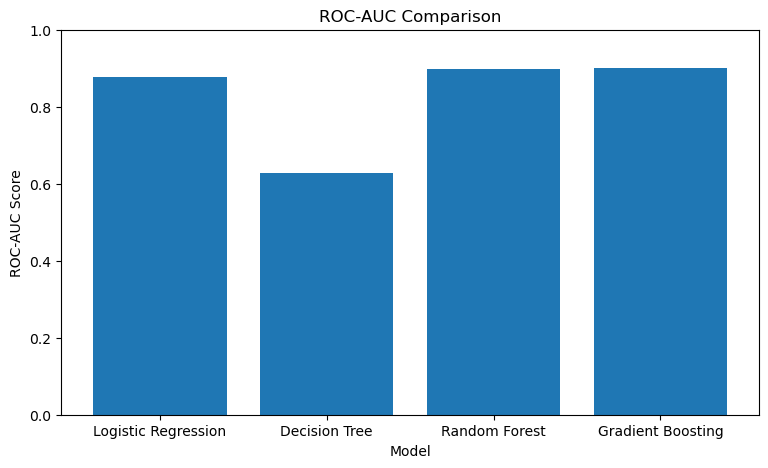

In [123]:
plt.figure(figsize=(9, 5))

plt.bar(
    roc_auc_results["Model"],
    roc_auc_results["ROC-AUC"]
)

plt.title("ROC-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.show()

In [124]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_tree,
        accuracy_rf,
        accuracy_gb
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_logistic),
        roc_auc_score(y_test, y_prob_tree),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb)
    ]
})

final_model_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.903,0.487179,0.197917,0.281481,0.876348
1,Decision Tree,0.856,0.289474,0.343750,0.314286,0.627074
2,Random Forest,0.905,0.526316,0.104167,0.173913,0.896749
3,Gradient Boosting,0.903,0.483871,0.156250,0.236220,0.900149


In [126]:
## ROC Curve Function for show AUC

In [127]:
from sklearn.metrics import roc_curve

In [128]:
fpr_logistic, tpr_logistic, _ = roc_curve(
    y_test,
    y_prob_logistic
)

In [129]:
fpr_tree, tpr_tree, _ = roc_curve(
    y_test,
    y_prob_tree
)

In [136]:
fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_prob_rf
)

In [131]:
fpr_gb, tpr_gb, _ = roc_curve(
    y_test,
    y_prob_gb
)

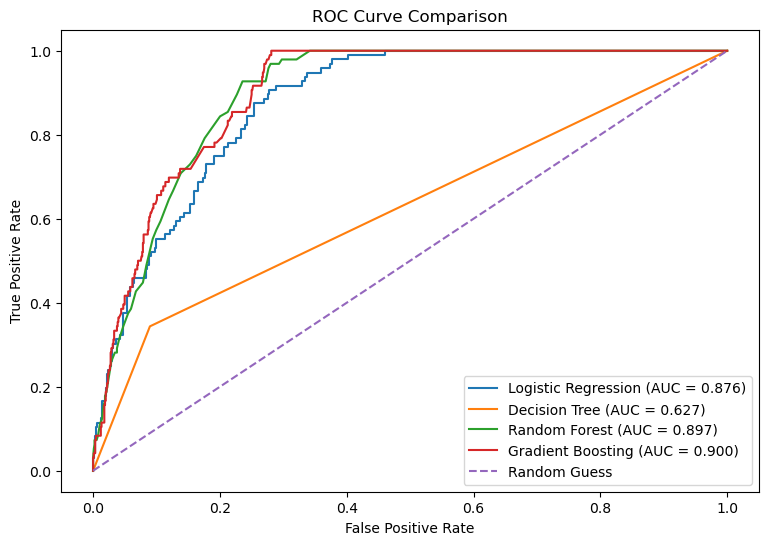

In [138]:
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_logistic,
    tpr_logistic,
    label=f"Logistic Regression (AUC = {roc_auc_results.loc[0, 'ROC-AUC']:.3f})"
)

plt.plot(
    fpr_tree,
    tpr_tree,
    label=f"Decision Tree (AUC = {roc_auc_results.loc[1, 'ROC-AUC']:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {roc_auc_results.loc[2, 'ROC-AUC']:.3f})"
)

plt.plot(
    fpr_gb,
    tpr_gb,
    label=f"Gradient Boosting (AUC = {roc_auc_results.loc[3, 'ROC-AUC']:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [140]:
final_model_comparison.to_csv(
    "../data/cleaned/model_comparison.csv",
    index=False
)

In [141]:
check_comparison = pd.read_csv(
    "../data/cleaned/model_comparison.csv"
)

check_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.903,0.487179,0.197917,0.281481,0.876348
1,Decision Tree,0.856,0.289474,0.343750,0.314286,0.627074
2,Random Forest,0.905,0.526316,0.104167,0.173913,0.896749
3,Gradient Boosting,0.903,0.483871,0.156250,0.236220,0.900149


In [148]:
final_model_comparison = final_model_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

final_model_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.903,0.483871,0.156250,0.236220,0.900149
1,Random Forest,0.905,0.526316,0.104167,0.173913,0.896749
2,Logistic Regression,0.903,0.487179,0.197917,0.281481,0.876348
3,Decision Tree,0.856,0.289474,0.343750,0.314286,0.627074


In [144]:
## Final Model- Gradient Boosting

In [149]:
final_model = gradient_boosting_model

In [150]:
final_predictions = final_model.predict(
    X_test
)

In [151]:
fraud_predictions = X_test.copy()

fraud_predictions["Actual_Fraudulent"] = y_test.values
fraud_predictions["Predicted_Fraudulent"] = final_predictions

In [152]:
fraud_predictions["Fraud_Probability"] = final_model.predict_proba(
    X_test
)[:, 1]

In [153]:
fraud_predictions.head(20)

,Transaction_Amount,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Transaction_Hour,Transaction_Month,Amount_vs_Average,Merchant_Category_Entertainment,Merchant_Category_Fashion,...,Location_Chennai,Location_Delhi,Location_Hyderabad,Location_Kolkata,Location_Mumbai,Location_Pune,Suspicious_Keyword_Yes,Actual_Fraudulent,Predicted_Fraudulent,Fraud_Probability
1854,200.99,0,4,38.62,275,4,4,5.204298,0,0,...,0,0,0,1,0,0,1,0,0,0.392550
4390,16.39,0,128,397.07,725,7,6,0.041277,1,0,...,0,1,0,0,0,0,0,0,0,0.006527
3651,40.58,0,47,292.00,1913,14,9,0.138973,0,0,...,0,0,0,0,1,0,1,1,0,0.315637
2255,67.85,0,117,379.53,653,17,4,0.178774,0,0,...,0,0,0,0,1,0,0,0,0,0.006527
894,88.23,0,144,261.28,1213,21,10,0.337684,1,0,...,0,1,0,0,0,0,0,0,0,0.006527
1286,7.36,0,16,391.10,807,22,10,0.018819,0,0,...,1,0,0,0,0,0,0,0,0,0.006342
486,3.72,0,173,55.87,348,5,2,0.066583,0,0,...,0,0,0,1,0,0,0,0,0,0.177443
343,45.51,1,60,221.03,574,15,6,0.205900,1,0,...,0,0,0,0,0,0,0,1,0,0.302329
1174,80.41,0,179,18.55,1892,7,7,4.334771,0,1,...,0,1,0,0,0,0,0,0,0,0.006043
65,62.59,0,166,49.74,1929,20,3,1.258343,1,0,...,0,1,0,0,0,0,0,0,0,0.005836


In [154]:
fraud_predictions.to_csv(
    "../data/cleaned/fraud_predictions.csv",
    index=False
)

In [155]:
check_predictions = pd.read_csv(
    "../data/cleaned/fraud_predictions.csv"
)

print("Shape:", check_predictions.shape)
check_predictions.head()

Shape: (1000, 31)


,Transaction_Amount,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Transaction_Hour,Transaction_Month,Amount_vs_Average,Merchant_Category_Entertainment,Merchant_Category_Fashion,...,Location_Chennai,Location_Delhi,Location_Hyderabad,Location_Kolkata,Location_Mumbai,Location_Pune,Suspicious_Keyword_Yes,Actual_Fraudulent,Predicted_Fraudulent,Fraud_Probability
0,200.99,0,4,38.62,275,4,4,5.204298,0,0,...,0,0,0,1,0,0,1,0,0,0.392550
1,16.39,0,128,397.07,725,7,6,0.041277,1,0,...,0,1,0,0,0,0,0,0,0,0.006527
2,40.58,0,47,292.00,1913,14,9,0.138973,0,0,...,0,0,0,0,1,0,1,1,0,0.315637
3,67.85,0,117,379.53,653,17,4,0.178774,0,0,...,0,0,0,0,1,0,0,0,0,0.006527
4,88.23,0,144,261.28,1213,21,10,0.337684,1,0,...,0,1,0,0,0,0,0,0,0,0.006527
